In [36]:
!pip install git+https://github.com/andreinechaev/nvcc4jupyter.git
%load_ext nvcc4jupyter

  Cloning https://github.com/andreinechaev/nvcc4jupyter.git to /tmp/pip-req-build-sae2u2re
  Running command git clone --filter=blob:none --quiet https://github.com/andreinechaev/nvcc4jupyter.git /tmp/pip-req-build-sae2u2re
  Resolved https://github.com/andreinechaev/nvcc4jupyter.git to commit 173e636d9a3cb81c6101a160c1c8c86864eaaf5b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
The nvcc4jupyter extension is already loaded. To reload it, use:
  %reload_ext nvcc4jupyter


In [37]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0


In [39]:
%load_ext nvcc4jupyter


The nvcc4jupyter extension is already loaded. To reload it, use:
  %reload_ext nvcc4jupyter


In [40]:
from pathlib import Path

file_path = Path('/absolute/path/to/images.jpg')
if file_path.exists():
    print("File exists!")
else:
    print("File does not exist!")

File does not exist!


In [41]:
import os
print("Current Working Directory:", os.getcwd())

Current Working Directory: /content


In [42]:
from google.colab import files
uploaded = files.upload()

Saving images.jpg to images (1).jpg


In [43]:
from pathlib import Path

# Assuming the file is in the same directory as the notebook
file_path = Path('images.jpg')
if file_path.exists():
    print("File exists!")
else:
    print("File does not exist!")

File exists!


In [44]:
pwd

'/content'

In [45]:
ls /content/images.jpg

/content/images.jpg


In [46]:
import cv2
image = cv2.imread('/content/images.jpg')
if image is None:
    print("Error: Image not found or unable to read the image.")
else:
    print("Image read successfully.")


Image read successfully.


In [47]:
%%writefile sobelEdgeDetectionFilter.cu
#include<stdio.h>
#include<stdlib.h>
#include<math.h>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

using namespace cv;

__global__ void sobelFilter(unsigned char *srcImage, unsigned char *dstImage, unsigned int width, unsigned int height) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;

    float Kx[3][3] = { {-1, 0, 1}, {-2, 0, 2}, {-1, 0, 1} };
    float Ky[3][3] = { {1, 2, 1}, {0, 0, 0}, {-1, -2, -1} };

    if ((x >= 1) && (x < (width - 1)) && (y >= 1) && (y < (height - 1))) {
        float Gx = 0;
        for (int ky = -1; ky <= 1; ky++) {
            for (int kx = -1; kx <= 1; kx++) {
                float fl = srcImage[((y + ky) * width + (x + kx))];
                Gx += fl * Kx[ky + 1][kx + 1];
            }
        }
        float Gx_abs = Gx < 0 ? -Gx : Gx;

        float Gy = 0;
        for (int ky = -1; ky <= 1; ky++) {
            for (int kx = -1; kx <= 1; kx++) {
                float fl = srcImage[((y + ky) * width + (x + kx))];
                Gy += fl * Ky[ky + 1][kx + 1];
            }
        }
        float Gy_abs = Gy < 0 ? -Gy : Gy;

        dstImage[(y * width + x)] = (unsigned char)fminf(Gx_abs + Gy_abs, 255.0f);
    }
}

void checkCudaErrors(cudaError_t r) {
    if (r != cudaSuccess) {
        fprintf(stderr, "CUDA Error: %s\n", cudaGetErrorString(r));
        exit(EXIT_FAILURE);
    }
}

int main() {
    Mat image = imread("/content/images.jpg", IMREAD_GRAYSCALE);

    if (image.empty()) {
        printf("Error: Image not found.\n");
        return -1;
    }

    int width = image.cols;
    int height = image.rows;
    size_t imageSize = width * height * sizeof(unsigned char);

    unsigned char *h_outputImage = (unsigned char *)malloc(imageSize);
    if (h_outputImage == nullptr) {
        fprintf(stderr, "Failed to allocate host memory\n");
        return -1;
    }

    unsigned char *d_inputImage, *d_outputImage;
    checkCudaErrors(cudaMalloc(&d_inputImage, imageSize));
    checkCudaErrors(cudaMalloc(&d_outputImage, imageSize));
    checkCudaErrors(cudaMemcpy(d_inputImage, image.data, imageSize, cudaMemcpyHostToDevice));

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    dim3 blockSize(16, 16);
    dim3 gridSize((width + 15) / 16, (height + 15) / 16);

    cudaEventRecord(start);
    sobelFilter<<<gridSize, blockSize>>>(d_inputImage, d_outputImage, width, height);
    cudaEventRecord(stop);

    cudaEventSynchronize(stop);

    float milliseconds = 0;
    cudaEventElapsedTime(&milliseconds, start, stop);

    checkCudaErrors(cudaMemcpy(h_outputImage, d_outputImage, imageSize, cudaMemcpyDeviceToHost));

    Mat outputImage(height, width, CV_8UC1, h_outputImage);
    imwrite("/content/output_sobel.jpg", outputImage);

    free(h_outputImage);
    cudaFree(d_inputImage);
    cudaFree(d_outputImage);
    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    printf("Total time taken: %f milliseconds\n", milliseconds);
    return 0;
}

Overwriting sobelEdgeDetectionFilter.cu


In [48]:
!apt-get update -qq
!apt-get install -y libopencv-dev pkg-config

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
E: dpkg was interrupted, you must manually run 'dpkg --configure -a' to correct the problem. 


In [49]:
!pkg-config --modversion opencv4

4.6.0


In [50]:
!nvcc -o sobelEdgeDetectionFilter sobelEdgeDetectionFilter.cu `pkg-config --cflags --libs opencv4`

/usr/include/opencv4/opencv2/stitching/detail/warpers.hpp(235): warning #611-D: overloaded virtual function "cv::detail::PlaneWarper::buildMaps" is only partially overridden in class "cv::detail::AffineWarper"
  class AffineWarper : public PlaneWarper
        ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

/usr/include/opencv4/opencv2/stitching/detail/warpers.hpp(235): warning #611-D: overloaded virtual function "cv::detail::PlaneWarper::warp" is only partially overridden in class "cv::detail::AffineWarper"
  class AffineWarper : public PlaneWarper
        ^

/usr/include/opencv4/opencv2/stitching/detail/blenders.hpp(100): warning #611-D: overloaded virtual function "cv::detail::Blender::prepare" is only partially overridden in class "cv::detail::FeatherBlender"
  class FeatherBlender : public Blender
        ^

/usr/include/opencv4/opencv2/stitching/detail/blenders.hpp(127): warning #611-D: overloaded virtual function "cv::detail::Blender::prepare" is

In [51]:
!./sobelEdgeDetectionFilter

Total time taken: 0.145312 milliseconds


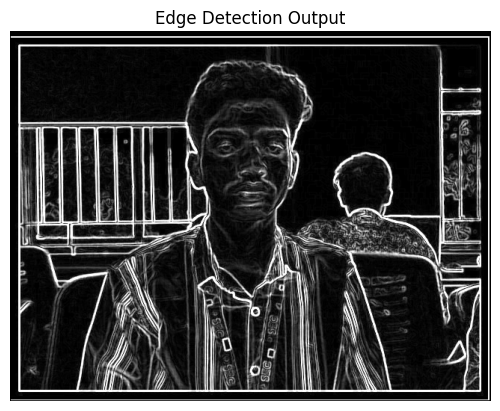

In [52]:
import cv2
from matplotlib import pyplot as plt
import os

# Read and display the output image
output_image_path = '/content/output_sobel.jpg'

if not os.path.exists(output_image_path):
    print(f"Error: The file '{output_image_path}' was not found. Please compile and run the Sobel filter program successfully first.")
else:
    output_image = cv2.imread(output_image_path, cv2.IMREAD_GRAYSCALE)
    if output_image is None:
        print("Error: Unable to load the image.")
    else:
        # Display the image
        plt.imshow(output_image, cmap='gray')
        plt.title('Edge Detection Output')
        plt.axis('off')  # Hide the axes
        plt.show()